# Calculative Foundation

## Application of Linear Algebra in Student Performance Analysis

### Problem Statement
A research institute has shared a dataset containing students' performance scores across multiple subjects. As a data analyst, the task is to apply Linear Algebra techniques to represent and manipulate data using vectors and matrices, perform advanced vector operations, and interpret eigenvalues and eigenvectors to understand variance in the dataset.

### Objectives
1. Represent student performance data using vectors and matrices.
2. Perform advanced operations such as dot product, cross product, vector projection, L1 norm, and L2 norm.
3. Interpret eigenvalues and eigenvectors to understand variation in student performance.

### Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Expected Outcome
To understand and apply Linear Algebra concepts to student performance data through theoretical explanations, manual calculations, and Python practical implementations.

## Part A: Vector & Matrix Fundamentals

In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:

df = pd.read_csv(r"C:\Users\tejpa\OneDrive\Documents\R & W Projects\Maths & Advance Statistics\Pr 4 Calculative Foundation\Data\Student_performance.csv")

### 1. Represent each student's subject scores as a vector.

In [55]:
subjects = [
    "Python", "SQL", "Excel",
    "Power_BI", "Business_Case_Study",
    "Mathematics_Advanced_Statistics",
    "DPF", "DSA", "DCI", "GenAI_AI_ML",
    "RM", "SP", "SL", "ULP", "NLP"
]

In [56]:
# First student's scores as a vector
v1 = df.loc[0, subjects].to_numpy()

print("Student ID:", df.loc[0, "Student_ID"])
print("Student Vector:")
print(v1)
print("Vector shape:", v1.shape)
print("Number of subjects:", len(v1))

Student ID: DSAI0001
Student Vector:
[83 49 75 59 46 63 55 72 51 66 66 58 48 53 52]
Vector shape: (15,)
Number of subjects: 15


### 2. Compute

#### Norm-1 and Norm-2 of vectors. 

In [57]:
# Calculate L1 Norm and L2 Norm

l1_norm = np.linalg.norm(v1, ord=1)
l2_norm = np.linalg.norm(v1, ord=2)

print("Student Vector:", v1)
print("L1 Norm:", l1_norm)
print("L2 Norm:", round(l2_norm, 2))

Student Vector: [83 49 75 59 46 63 55 72 51 66 66 58 48 53 52]
L1 Norm: 896.0
L2 Norm: 234.91


In [58]:
# Convert all 15 subject scores into a matrix
score_matrix = df[subjects].to_numpy()

In [59]:
# Calculate norms for every student
df["L1_Norm"] = np.linalg.norm(score_matrix, ord=1, axis=1)
df["L2_Norm"] = np.linalg.norm(score_matrix, ord=2, axis=1)

# Display the results
print(df[["Student_ID", "L1_Norm", "L2_Norm"]].head())

  Student_ID  L1_Norm     L2_Norm
0   DSAI0001    896.0  234.912750
1   DSAI0002   1166.0  302.905926
2   DSAI0003   1019.0  266.411336
3   DSAI0004    878.0  231.568564
4   DSAI0005    892.0  232.551070


#### Interpretation
The L1 Norm is calculated as the sum of the absolute subject scores, while the L2 Norm is calculated as the square root of the sum of squared subject scores. These norms provide two different mathematical measures of the magnitude of each student's score vector.

#### Dot product and angle between two students’ score vectors.

In [60]:
# Select two students' score vectors
v1 = df.loc[0, subjects].to_numpy(dtype=float)
v2 = df.loc[1, subjects].to_numpy(dtype=float)

In [61]:
# Calculate dot product
dot_product = np.dot(v1, v2)

print("Student 1 ID:", df.loc[0, "Student_ID"])
print("Student 2 ID:", df.loc[1, "Student_ID"])

print("Student 1 Vector:", v1)
print("Student 2 Vector:", v2)

print("Dot Product:", dot_product)

Student 1 ID: DSAI0001
Student 2 ID: DSAI0002
Student 1 Vector: [83. 49. 75. 59. 46. 63. 55. 72. 51. 66. 66. 58. 48. 53. 52.]
Student 2 Vector: [91. 82. 82. 87. 80. 61. 75. 71. 67. 81. 81. 66. 70. 84. 88.]
Dot Product: 69939.0


##### Interpretation
Dot Product positive, zero ke negative hoi shake chhe, depending on the vector values.

#### Angle between two vectors

In [62]:
# Calculate vector magnitudes
norm_v1 = np.linalg.norm(v1)
norm_v2 = np.linalg.norm(v2)

In [63]:
# Calculate cosine of the angle
cos_theta = np.dot(v1, v2) / (norm_v1 * norm_v2)

In [64]:
# Protect against floating-point rounding
cos_theta = np.clip(cos_theta, -1, 1)

In [65]:
# Convert angle from radians to degrees
angle_degrees = np.degrees(np.arccos(cos_theta))

print("Angle between students:", round(angle_degrees, 2), "degrees")

Angle between students: 10.61 degrees


##### Interpretation
The angle between two student score vectors indicates the directional similarity of their subject-score patterns. A smaller angle generally indicates more similar relative score patterns, while a larger angle indicates less directional similarity.

#### Cross product(for 3D Selected Subjects)

In [66]:
# Select three subjects for 3D vectors
subjects_3d = ["Python", "SQL", "Excel"]

In [67]:
# Get two students' scores
A = df.loc[0, subjects_3d].to_numpy(dtype=float)
B = df.loc[1, subjects_3d].to_numpy(dtype=float)

In [68]:
# Calculate cross product
cross_product = np.cross(A, B)

print("Student 1:", df.loc[0, "Student_ID"])
print("Vector A:", A)
print("Student 2:", df.loc[1, "Student_ID"])
print("Vector B:", B)
print("Cross Product:", cross_product)

Student 1: DSAI0001
Vector A: [83. 49. 75.]
Student 2: DSAI0002
Vector B: [91. 82. 82.]
Cross Product: [-2132.    19.  2347.]


In [69]:
# verify that the result is perpendicular 
print("A dot (A x B):", np.dot(A, cross_product))
print("B dot (A x B):", np.dot(B, cross_product))

A dot (A x B): 0.0
B dot (A x B): 0.0


#### Interpretation
The cross product of two selected three-dimensional student score vectors produces a vector perpendicular to both original vectors. It demonstrates the application of vector operations in three-dimensional space.

#### 3. Find the projection of one vector onto another

The vector projection of vector onto vector is the component of that lies along the direction of.

In [70]:
subjects_3d = ["Python", "SQL", "Excel"]

In [71]:
# Select two students
A = df.loc[0, subjects_3d].to_numpy(dtype=float)
B = df.loc[1, subjects_3d].to_numpy(dtype=float)

In [72]:
# Calculate vector projection of A onto B
denominator = np.dot(B, B)

In [73]:
if denominator != 0:
    projection_A_on_B = (np.dot(A, B) / denominator) * B

    print("Student A:", df.loc[0, "Student_ID"])
    print("Vector A:", A)

    print("Student B:", df.loc[1, "Student_ID"])
    print("Vector B:", B)

    print("Projection of A onto B:", projection_A_on_B)
else:
    print("Projection is undefined because vector B is zero.")

Student A: DSAI0001
Vector A: [83. 49. 75.]
Student B: DSAI0002
Vector B: [91. 82. 82.]
Projection of A onto B: [74.21469005 66.87477565 66.87477565]


## Part B: Matrix Operation

#### From a matrix of students x subjects perform.

A matrix is actangular arrangement of numerical elements organized into rows and coloumns.

In [74]:
# Convert subject scores into a matrix
score_matrix = df[subjects].to_numpy(dtype=float)
print("Matrix Shape:", score_matrix.shape)

Matrix Shape: (5000, 15)


In [75]:
print("\nFirst 5 students' scores:\n", score_matrix[:5])


First 5 students' scores:
 [[83. 49. 75. 59. 46. 63. 55. 72. 51. 66. 66. 58. 48. 53. 52.]
 [91. 82. 82. 87. 80. 61. 75. 71. 67. 81. 81. 66. 70. 84. 88.]
 [63. 62. 92. 68. 72. 64. 51. 79. 67. 62. 51. 78. 73. 79. 58.]
 [62. 42. 63. 43. 45. 64. 70. 62. 72. 38. 74. 74. 64. 61. 44.]
 [46. 69. 65. 66. 68. 51. 58. 42. 62. 68. 49. 58. 64. 64. 62.]]


#### Matrix Addition

In [76]:
# Example matrices for demonstrating addition
A = np.array([
    [10, 20],
    [30, 40]
])

B = np.array([
    [1, 2],
    [3, 4]
])

matrix_sum = A + B

print("Matrix A:\n", A)


Matrix A:
 [[10 20]
 [30 40]]


In [77]:
print("Matrix B:\n", B)

Matrix B:
 [[1 2]
 [3 4]]


In [78]:
print("A + B:\n", matrix_sum)

A + B:
 [[11 22]
 [33 44]]


#### Matrix Multiplication

In [79]:
# X contains the 15 subject scores for all students
X = df[subjects].to_numpy(dtype=float)

print("Original Matrix Shape:", X.shape)

Original Matrix Shape: (5000, 15)


In [80]:
# Matrix multiplication: transpose of X multiplied by X
product_matrix = X.T @ X

print("Transpose Shape:", X.T.shape)
print("Product Matrix Shape:", product_matrix.shape)


Transpose Shape: (15, 5000)
Product Matrix Shape: (15, 15)


In [81]:
# Display the resulting matrix
product_df = pd.DataFrame(
    product_matrix,
    index=subjects,
    columns=subjects
)

display(product_df.round(2))

,Python,SQL,Excel,Power_BI,Business_Case_Study,Mathematics_Advanced_Statistics,DPF,DSA,DCI,GenAI_AI_ML,RM,SP,SL,ULP,NLP
Python,19163852.0,17248604.0,19005753.0,19275709.0,16178202.0,16878499.0,18400327.0,17887165.0,18309277.0,17357803.0,19194998.0,19061349.0,18340295.0,19482001.0,18803531.0
SQL,17248604.0,16403530.0,17548962.0,17793486.0,14949289.0,15577913.0,16982788.0,16504541.0,16893008.0,16031945.0,17709833.0,17571889.0,16924049.0,17963385.0,17348994.0
Excel,19005753.0,17548962.0,19803291.0,19610440.0,16441949.0,17158907.0,18715835.0,18188188.0,18607511.0,17655083.0,19529552.0,19386584.0,18668377.0,19807306.0,19125653.0
Power_BI,19275709.0,17793486.0,19610440.0,20347316.0,16671547.0,17388032.0,18973705.0,18456862.0,18864908.0,17910101.0,19794789.0,19646403.0,18918051.0,20073249.0,19390873.0
Business_Case_Study,16178202.0,14949289.0,16441949.0,16671547.0,14496360.0,14619583.0,15931794.0,15482515.0,15850093.0,15052421.0,16608868.0,16483538.0,15873652.0,16852910.0,16272220.0
Mathematics_Advanced_Statistics,16878499.0,15577913.0,17158907.0,17388032.0,14619583.0,15708861.0,16609003.0,16155711.0,16537009.0,15683688.0,17328509.0,17193018.0,16564905.0,17585997.0,16984339.0
DPF,18400327.0,16982788.0,18715835.0,18973705.0,15931794.0,16609003.0,18577747.0,17606764.0,18014764.0,17096414.0,18905609.0,18763357.0,18070958.0,19181159.0,18519388.0
DSA,17887165.0,16504541.0,18188188.0,18456862.0,15482515.0,16155711.0,17606764.0,17574182.0,17516340.0,16611609.0,18372372.0,18229250.0,17562770.0,18640472.0,17983031.0
DCI,18309277.0,16893008.0,18607511.0,18864908.0,15850093.0,16537009.0,18014764.0,17516340.0,18386410.0,17007647.0,18800877.0,18659474.0,17968145.0,19083484.0,18406301.0
GenAI_AI_ML,17357803.0,16031945.0,17655083.0,17910101.0,15052421.0,15683688.0,17096414.0,16611609.0,17007647.0,16627324.0,17835383.0,17694446.0,17054888.0,18095736.0,17463130.0


##### Interpretation:
Matrix multiplication was performed on the transpose of the student score matrix and the 
original score matrix. The resulting 15 × 15 matrix contains the sums of pairwise products 
between subject scores across all students.

#### Matric Transpose

In [82]:
transpose_matrix = X.T

print("Original Matrix:", X.shape)
print("Transpose Matrix:", transpose_matrix.shape)


Original Matrix: (5000, 15)
Transpose Matrix: (15, 5000)


In [83]:
# Display the first 5 student columns and first 5 subject rows
print(transpose_matrix[:5, :5])

[[83. 91. 63. 62. 46.]
 [49. 82. 62. 42. 69.]
 [75. 82. 92. 63. 65.]
 [59. 87. 68. 43. 66.]
 [46. 80. 72. 45. 68.]]


##### Interpretation:
In the original matrix, rows represent students. After transposing, rows represent subjects and columns represent students.

#### Determinant

The determinant is a scalar value associated with a square matrix that provides information about properties such as invertibility.

In [84]:
import numpy as np

A = np.array([
    [4, 2],
    [3, 5]
])

det_A = np.linalg.det(A)

print("Matrix A:\n", A)


Matrix A:
 [[4 2]
 [3 5]]


In [85]:
print("Determinant:", round(det_A, 2))

Determinant: 14.0


#### Inverse

In [86]:
inverse_A = np.linalg.inv(A)

print("Original Matrix:\n", A)


Original Matrix:
 [[4 2]
 [3 5]]


In [87]:
print("Inverse Matrix:\n", inverse_A)

Inverse Matrix:
 [[ 0.35714286 -0.14285714]
 [-0.21428571  0.28571429]]


In [88]:
# Verify the inverse
print("A multiplied by inverse:\n", A @ inverse_A)

A multiplied by inverse:
 [[1.00000000e+00 0.00000000e+00]
 [2.77555756e-17 1.00000000e+00]]


In [89]:
# Create a square matrix from the score matrix
square_matrix = X.T @ X

print("Square Matrix Shape:", square_matrix.shape)
print("Matrix Rank:", np.linalg.matrix_rank(square_matrix))

Square Matrix Shape: (15, 15)
Matrix Rank: 15


In [90]:
# Check whether the matrix is invertible
if np.linalg.matrix_rank(square_matrix) == square_matrix.shape[0]:
    inverse_matrix = np.linalg.inv(square_matrix)
    print("Inverse exists.")
else:
    print("Matrix is singular; ordinary inverse does not exist.")

Inverse exists.


## Part C: Linear Transformations & Geometry

A line in two-dimensional space can be represented by a linear equation such as:

y = mx + c
m = slope
c = y-intercept

In [92]:
# Select two subject scores
x = df["Python"].to_numpy(dtype=float)
y = df["SQL"].to_numpy(dtype=float)

# Fit a straight line: y = mx + c
m, c = np.polyfit(x, y, 1)

print("Slope:", round(m, 3))
print("Intercept:", round(c, 3))

Slope: 0.72
Intercept: 11.659


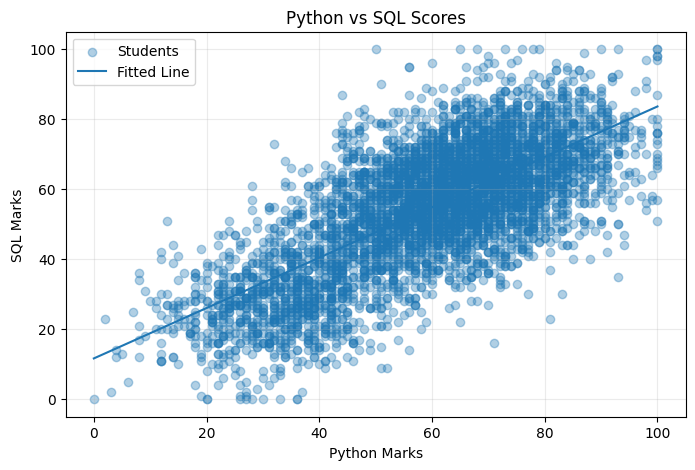

In [93]:
# Plot student scores
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.35, label="Students")

# Plot the fitted line
x_line = np.linspace(x.min(), x.max(), 100)
y_line = m * x_line + c
plt.plot(x_line, y_line, label="Fitted Line")

plt.xlabel("Python Marks")
plt.ylabel("SQL Marks")
plt.title("Python vs SQL Scores")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

A scatter plot was created using Python and SQL marks. A best-fit straight line was added to observe the linear trend between the two subjects. The slope indicates the direction of the estimated relationship.

#### Plane

A plane is a two-dimensional flat surface that extends infinitely in three-dimensional space.
Plane ni equation:



##### Definition
A plane is a flat, two-dimensional surface in three-dimensional space.

##### Equation
ax + by + cz = d

##### Objective
To visualize student performance using three subject scores and understand the concept of a plane in 3D geometry.

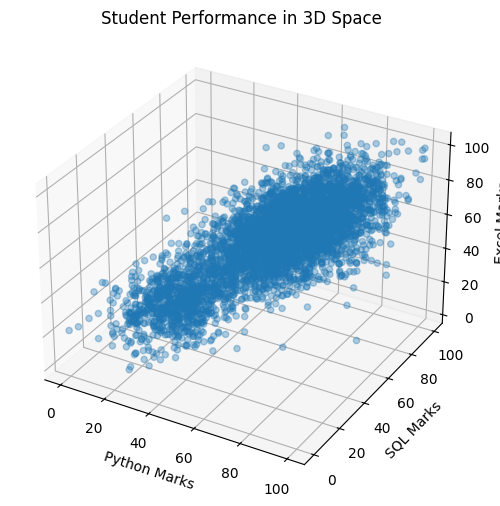

In [94]:
# Select three subject scores
x = df["Python"]
y = df["SQL"]
z = df["Excel"]

# Create a 3D scatter plot
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(x, y, z, alpha=0.35)

ax.set_xlabel("Python Marks")
ax.set_ylabel("SQL Marks")
ax.set_zlabel("Excel Marks")

ax.set_title("Student Performance in 3D Space")

plt.show()

A 3D scatter plot was created using Python, SQL, and Excel marks. Each student is represented as a point in three-dimensional space. This visualization helps demonstrate how multiple subject scores can be represented geometrically.

#### Concept: Hyperplane.

##### Definition
A hyperplane is a flat surface that separates or represents regions in a higher-dimensional space.

##### Equation
w1*x1 + w2*x2 + ... + wn*xn = b

##### Objective
To understand how hyperplanes represent linear boundaries in higher-dimensional data.

In [95]:
# Select the 15 subject features
subjects = [
    "Python", "SQL", "Excel", "Power_BI",
    "Business_Case_Study", "Mathematics_Advanced_Statistics",
    "DPF", "DSA", "DCI", "GenAI_AI_ML",
    "RM", "SP", "SL", "ULP", "NLP"
]



In [97]:
# Create the feature matrix
X = df[subjects].to_numpy(dtype=float)

In [98]:
print("Number of students:", X.shape[0])
print("Number of subject features:", X.shape[1])
print("Feature matrix shape:", X.shape)

Number of students: 5000
Number of subject features: 15
Feature matrix shape: (5000, 15)


In [99]:
x = df["Python"].to_numpy(dtype=float)
y = df["SQL"].to_numpy(dtype=float)

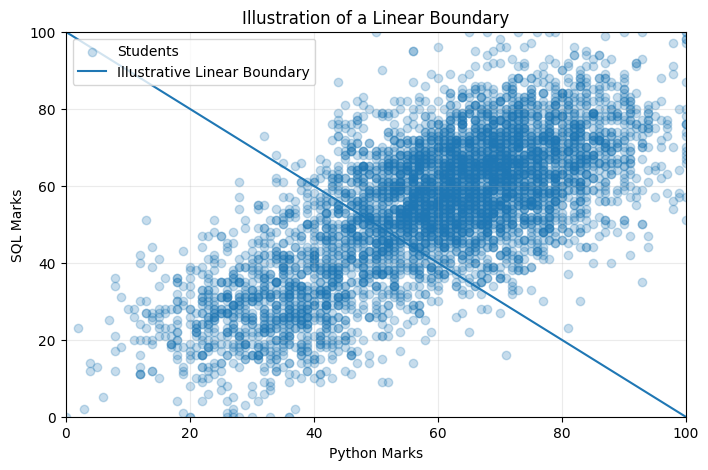

In [100]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, alpha=0.25, label="Students")

# Illustrative boundary: SQL = 100 - Python
x_line = np.linspace(0, 100, 100)
y_line = 100 - x_line

plt.plot(x_line, y_line, label="Illustrative Linear Boundary")

plt.xlabel("Python Marks")
plt.ylabel("SQL Marks")
plt.title("Illustration of a Linear Boundary")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

##### Interpretation
The dataset contains 5,000 students and 15 subject-score features. Therefore, each student can be represented as a point in a 15-dimensional feature space. A hyperplane can define a linear boundary in this space, for example, for classification tasks such as Pass/Fail prediction.

## Part D: Covariance Matrix

#### Definition
Covariance measures how two variables change together.

#### Types of Covariance
- Positive covariance: Variables tend to move in the same direction.
- Negative covariance: Variables tend to move in opposite directions.
- Near-zero covariance: Little linear co-movement is observed.

#### Objective
To calculate the covariance matrix of student subject scores and understand relationships between subjects.

In [102]:
subjects = [
    "Python", "SQL", "Excel", "Power_BI",
    "Business_Case_Study", "Mathematics_Advanced_Statistics",
    "DPF", "DSA", "DCI", "GenAI_AI_ML",
    "RM", "SP", "SL", "ULP", "NLP"
]

# Select subject scores
X = df[subjects].to_numpy(dtype=float)

# Calculate covariance matrix
cov_matrix = np.cov(X, rowvar=False)

cov_df = pd.DataFrame(
    cov_matrix,
    index=subjects,
    columns=subjects
)

print("Covariance Matrix Shape:", cov_matrix.shape)


Covariance Matrix Shape: (15, 15)


In [103]:
display(cov_df.round(2))

,Python,SQL,Excel,Power_BI,Business_Case_Study,Mathematics_Advanced_Statistics,DPF,DSA,DCI,GenAI_AI_ML,RM,SP,SL,ULP,NLP
Python,323.65,232.98,227.52,231.55,228.70,230.65,227.57,228.49,229.53,227.83,229.38,233.35,229.10,231.06,231.45
SQL,232.98,332.02,233.94,237.05,233.47,232.60,231.74,231.02,232.28,232.94,233.12,233.67,232.41,232.75,234.62
Excel,227.52,233.94,321.38,231.91,226.19,228.93,227.22,227.16,226.10,227.68,229.95,232.62,231.52,228.76,231.01
Power_BI,231.55,237.05,231.91,327.71,229.30,229.98,229.64,233.21,228.72,232.50,231.61,233.63,232.49,229.77,233.81
Business_Case_Study,228.70,233.47,226.19,229.30,322.68,228.96,227.95,226.84,228.90,230.97,228.73,229.97,227.93,229.79,230.26
Mathematics_Advanced_Statistics,230.65,232.60,228.93,229.98,228.96,323.06,227.52,229.67,231.20,229.56,230.60,231.01,230.83,232.16,233.79
DPF,227.57,231.74,227.22,229.64,227.95,227.52,318.80,226.47,226.03,227.91,229.77,231.52,230.75,230.06,231.59
DSA,228.49,231.02,227.16,233.21,226.84,229.67,226.47,318.81,227.64,226.68,229.64,230.32,230.60,230.09,228.47
DCI,229.53,232.28,226.10,228.72,228.90,231.20,226.03,227.64,320.12,228.81,229.57,231.32,229.96,231.60,229.26
GenAI_AI_ML,227.83,232.94,227.68,232.50,230.97,229.56,227.91,226.68,228.81,327.09,230.47,230.65,232.12,231.03,230.30


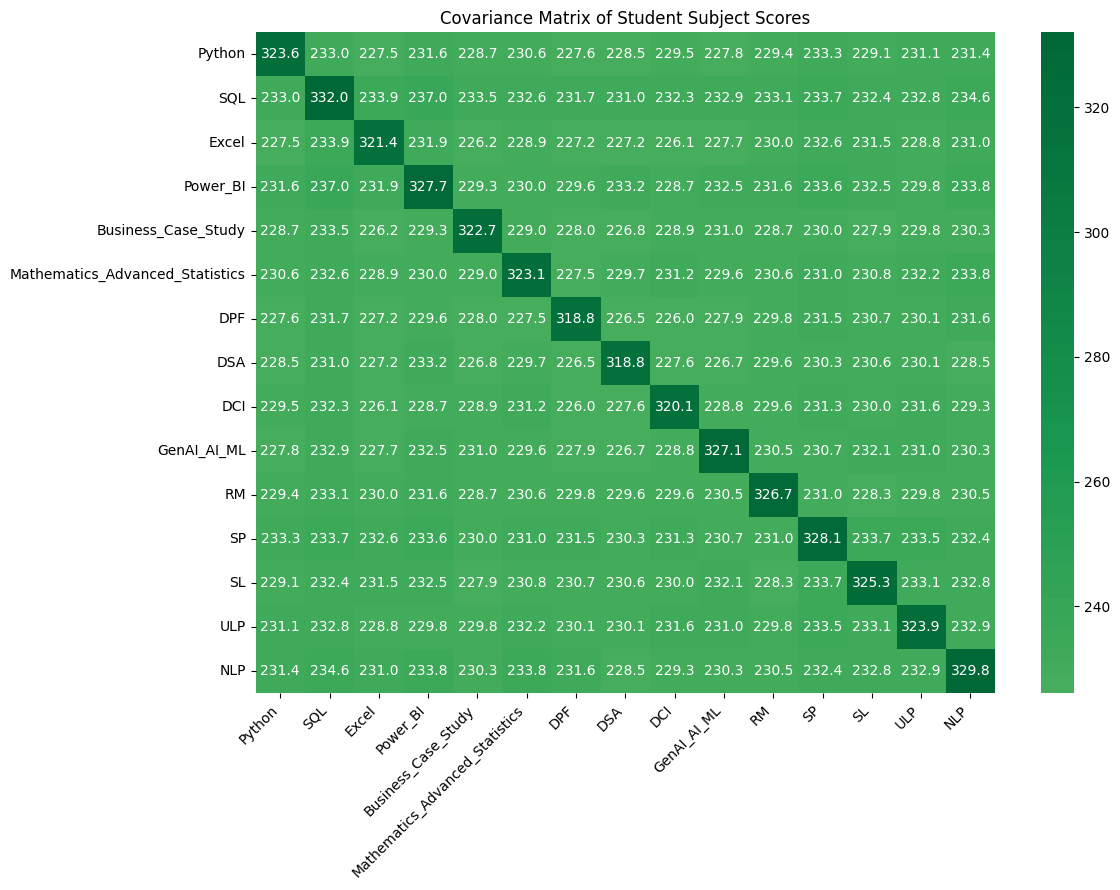

In [105]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    cov_df,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0
)

plt.title("Covariance Matrix of Student Subject Scores")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Interpretation:
The covariance matrix was calculated using the subject scores of 5,000 students. The resulting 15 × 15 matrix shows the direction and magnitude of the joint variation between subject scores. Positive covariance indicates that two subjects tend to vary in the same direction, while negative covariance indicates variation in opposite directions.

### Eigenvalues and Eigenvectors

#### Definition
An eigenvector is a non-zero vector whose direction remains unchanged when a square matrix is applied to it. The corresponding eigenvalue represents the scaling factor.

#### Formula
Av = λv

Where:
- A = Square matrix
- v = Eigenvector
- λ = Eigenvalue

#### Objective
To calculate the eigenvalues and eigenvectors of the covariance matrix and identify the directions with the largest variation in student performance.

In [107]:
subjects = [
    "Python", "SQL", "Excel", "Power_BI",
    "Business_Case_Study", "Mathematics_Advanced_Statistics",
    "DPF", "DSA", "DCI", "GenAI_AI_ML",
    "RM", "SP", "SL", "ULP", "NLP"
]

# Select the subject-score data
X = df[subjects].to_numpy(dtype=float)

# Calculate the covariance matrix
cov_matrix = np.cov(X, rowvar=False)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort them from largest to smallest eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

In [108]:
print("Covariance Matrix Shape:", cov_matrix.shape)

Covariance Matrix Shape: (15, 15)


In [109]:
print("\nEigenvalues:")
print(np.round(eigenvalues, 2))


Eigenvalues:
[3551.63  101.52  101.17   99.49   98.69   97.28   95.81   94.69   93.43
   91.8    90.5    89.89   89.33   87.5    86.36]


In [110]:
print("\nFirst Eigenvector:")
print(np.round(eigenvectors[:, 0], 3))


First Eigenvector:
[0.258 0.262 0.257 0.26  0.257 0.258 0.256 0.256 0.257 0.258 0.258 0.26
 0.259 0.259 0.26 ]


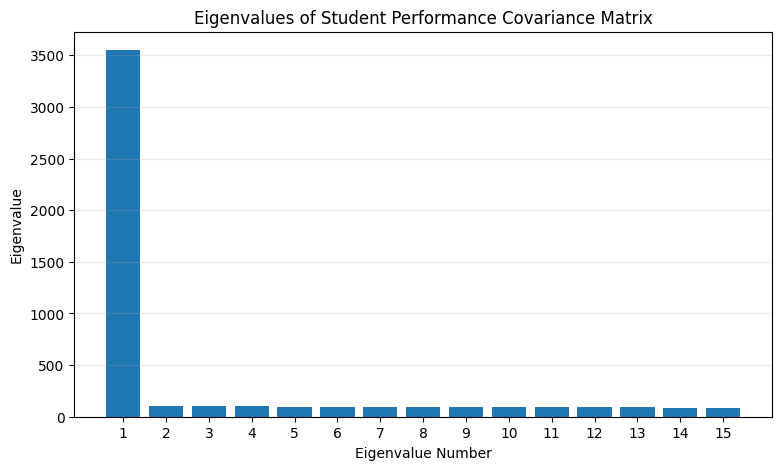

In [111]:
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(eigenvalues) + 1),
    eigenvalues
)

plt.xlabel("Eigenvalue Number")
plt.ylabel("Eigenvalue")
plt.title("Eigenvalues of Student Performance Covariance Matrix")
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(axis="y", alpha=0.25)

plt.show()

#### Interpretation
The eigenvalues and eigenvectors of the covariance matrix were calculated using NumPy. The eigenvalues represent the amount of variance associated with their corresponding eigenvectors. The eigenvector associated with the largest eigenvalue identifies the direction of maximum variance in the subject-score feature space.